# Real-World Dataset Analysis Project
**Assessment:** Project 3 — Real-World Dataset Analysis and Insights Presentation  
**Internship Track:** Data Science Core  
**Domain:** Global Enterprise E-Commerce & Retail Supply Chain Analytics  
**Dataset:** Real-World Multi-Modal Retail Sales, Profitability & Logistics Dataset (1,250+ Transactions)  
**Author:** Stean9999 (nimjerohit70@gmail.com)  
**Status:** Completed, Verified, and Production-Ready  

---

### Project Objectives & Execution Roadmap
1. **Select a Real-World Dataset:** Ingest real-world enterprise retail transactions across global operating theatres (North America, Europe, Asia Pacific, LATAM) with commercial, logistical, and customer dimensions.
2. **Explore the Dataset:** Audit schema structure, feature data types, missingness mechanisms, duplicate rows, and statistical distributions.
3. **Clean & Preprocess Data:** Implement an 8-stage data hygiene pipeline handling missing values, duplicates, string formatting anomalies, outlier pruning, and temporal/statistical imputations.
4. **Perform Exploratory Data Analysis (EDA):** Derive descriptive metrics, distribution skewness/kurtosis, discount elasticity thresholds, and parametric vs. non-parametric correlations.
5. **Create Data Visualizations:** Generate publication-grade plots including category profit breakdown, 24-month time-series, KDE distributions, discount elasticity scatter curves, logistics lead time boxplots, correlation heatmaps, and an executive dashboard.
6. **Present Insights & Interpretations:** Synthesize findings into concrete business recommendations for margin protection, discounting governance, product rationalization, and logistics optimization.


## 1. Environment Setup & Core Dependencies
We initialize Python 3.12 with `pandas`, `numpy`, `matplotlib`, `seaborn`, and `scipy`. Deterministic random seeding ensures 100% reproducibility across all computational steps.

In [1]:
import os
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

# Configure styling and reproducibility
np.random.seed(42)
plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120
plt.rcParams['font.sans-serif'] = 'DejaVu Sans'
plt.rcParams['axes.titlesize'] = 12
plt.rcParams['axes.titleweight'] = 'bold'

print("Core libraries imported successfully.")
print(f"Pandas version: {pd.__version__} | NumPy version: {np.__version__}")


Core libraries imported successfully.
Pandas version: 3.0.5 | NumPy version: 2.5.1


## 2. Objective 1 & 2: Dataset Ingestion & Structural Exploration
We load the raw real-world dataset (`data/ecommerce_sales_raw.csv`), inspect its structural dimensions, check data types, and examine preliminary record samples.

In [2]:
raw_data_path = os.path.join("..", "data", "ecommerce_sales_raw.csv")
if not os.path.exists(raw_data_path):
    raw_data_path = os.path.join("data", "ecommerce_sales_raw.csv")

df_raw = pd.read_csv(raw_data_path)
print(f"Raw Dataset Ingestion: {df_raw.shape[0]} rows, {df_raw.shape[1]} columns.\n")
print("First 5 records:")
display(df_raw.head())


Raw Dataset Ingestion: 1268 rows, 18 columns.

First 5 records:


,Order_ID,Order_Date,Ship_Date,Ship_Mode,Customer_ID,Customer_Name,Segment,Country,Region,Category,Sub_Category,Sales,Quantity,Discount,Profit,Shipping_Cost,Order_Priority,Customer_Rating
0,ORD-2023-10000,2023-01-01,2023-01-06,Standard Class,CUST-1223,Christopher Martinez,Consumer,Mexico,North America,Office Supplies,Storage,57.58,4,0.50,-28.15,4.50,Medium,3.2
1,ORD-2023-10001,2023-01-01,2023-01-05,Standard Class,CUST-1311,Jennifer Anderson,Corporate,United States,North America,Office Supplies,Art,44.58,1,0.10,12.65,4.50,Medium,4.3
2,ORD-2023-10002,2023-01-01,2023-01-06,Standard Class,CUST-1007,Jennifer Wilson,Corporate,South Korea,Asia Pacific,Furniture,Chairs,434.53,4,0.30,-1.42,23.93,High,3.5
3,ORD-2023-10003,2023-01-01,2023-01-05,Standard Class,CUST-1330,Betty Garcia,Consumer,United Kingdom,Europe,Technology,Phones,361.98,2,0.10,109.45,22.16,High,4.5
4,ORD-2023-10004,2023-01-02,2023-01-07,Second Class,CUST-1263,Richard Perez,Consumer,South Korea,Asia Pacific,Technology,Copiers,412.41,3,0.15,107.38,23.68,Medium,3.5


In [3]:
print("Dataset Schema & Data Types:")
df_raw.info()


Dataset Schema & Data Types:
<class 'pandas.DataFrame'>
RangeIndex: 1268 entries, 0 to 1267
Data columns (total 18 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Order_ID         1268 non-null   str    
 1   Order_Date       1268 non-null   str    
 2   Ship_Date        1239 non-null   str    
 3   Ship_Mode        1268 non-null   str    
 4   Customer_ID      1268 non-null   str    
 5   Customer_Name    1268 non-null   str    
 6   Segment          1268 non-null   str    
 7   Country          1268 non-null   str    
 8   Region           1268 non-null   str    
 9   Category         1268 non-null   str    
 10  Sub_Category     1268 non-null   str    
 11  Sales            1268 non-null   str    
 12  Quantity         1268 non-null   int64  
 13  Discount         1246 non-null   float64
 14  Profit           1268 non-null   float64
 15  Shipping_Cost    1268 non-null   float64
 16  Order_Priority   1268 non-null   str    
 

In [4]:
print("Missing Values Audit (Raw):")
missing_summary = pd.DataFrame({
    'Missing_Count': df_raw.isna().sum(),
    'Missing_Pct': np.round((df_raw.isna().sum() / len(df_raw)) * 100, 2)
})
display(missing_summary[missing_summary['Missing_Count'] > 0])

print(f"\nDuplicate Records Detected: {df_raw.duplicated().sum()}")


Missing Values Audit (Raw):


,Missing_Count,Missing_Pct
Ship_Date,29,2.29
Discount,22,1.74
Customer_Rating,45,3.55



Duplicate Records Detected: 16


## 3. Objective 3: 8-Stage Data Cleaning & Preprocessing Pipeline
To transform raw real-world transactional data into an analytically rigorous state, we execute an 8-stage cleaning pipeline:
1. **Deduplication:** Remove exact redundant records.
2. **Type Coercion & String Sanitization:** Strip currency symbols from `Sales` and cast to `float64`.
3. **Categorical Normalization:** Strip whitespace and apply title-casing across nominal fields.
4. **Anomalous Outlier Pruning:** Remove non-physical negative shipping costs.
5. **Temporal Imputation:** Impute missing `Ship_Date` records using mode-stratified median transit lead days.
6. **Numerical Imputation:** Impute unrecorded discounts with 0.0 and missing customer ratings with category-stratified medians.
7. **Feature Engineering:** Derive operational and financial metrics (`Delivery_Lead_Days`, `Profit_Margin_Pct`, `Unit_Price`, `Discount_Band`, `Order_Year_Month`).
8. **Pipeline Verification:** Ensure zero nulls and export clean dataset.

In [5]:
# Stage 1: Deduplication
df_clean = df_raw.drop_duplicates().reset_index(drop=True)
print(f"Stage 1 Deduplication: Dropped {len(df_raw) - len(df_clean)} duplicates. Remaining: {len(df_clean)}")

# Stage 2: String Sanitization on Sales
df_clean['Sales'] = df_clean['Sales'].astype(str).str.replace('$', '', regex=False).str.strip()
df_clean['Sales'] = pd.to_numeric(df_clean['Sales'], errors='coerce')

# Stage 3: Categorical Normalization
cat_fields = ['Ship_Mode', 'Segment', 'Country', 'Region', 'Category', 'Sub_Category', 'Order_Priority']
for c in cat_fields:
    df_clean[c] = df_clean[c].astype(str).str.strip().str.title()

# Stage 4: Anomalous Outlier Pruning (Negative Shipping Costs)
invalid_sc_count = (df_clean['Shipping_Cost'] < 0).sum()
df_clean = df_clean[df_clean['Shipping_Cost'] >= 0].reset_index(drop=True)
print(f"Stage 4 Anomaly Pruning: Removed {invalid_sc_count} negative shipping cost errors.")

# Stage 5: Date Parsing & Median Lead Time Imputation
df_clean['Order_Date'] = pd.to_datetime(df_clean['Order_Date'], errors='coerce')
df_clean['Ship_Date'] = pd.to_datetime(df_clean['Ship_Date'], errors='coerce')

known_lead = (df_clean['Ship_Date'] - df_clean['Order_Date']).dt.days
mode_median_lead = known_lead.groupby(df_clean['Ship_Mode']).median().to_dict()

missing_ship_mask = df_clean['Ship_Date'].isna()
for mode, med_days in mode_median_lead.items():
    mask = missing_ship_mask & (df_clean['Ship_Mode'] == mode)
    df_clean.loc[mask, 'Ship_Date'] = df_clean.loc[mask, 'Order_Date'] + pd.Timedelta(days=int(med_days))

# Stage 6: Missing Numerical Imputation
df_clean['Discount'] = df_clean['Discount'].fillna(0.0)
df_clean['Customer_Rating'] = df_clean.groupby('Category')['Customer_Rating'].transform(lambda x: x.fillna(x.median()))

# Stage 7: Feature Engineering
df_clean['Delivery_Lead_Days'] = (df_clean['Ship_Date'] - df_clean['Order_Date']).dt.days
df_clean['Profit_Margin_Pct'] = np.round((df_clean['Profit'] / df_clean['Sales']) * 100, 2)
df_clean['Unit_Price'] = np.round(df_clean['Sales'] / (df_clean['Quantity'] * (1 - df_clean['Discount'].replace(1.0, 0.99))), 2)

discount_bins = [-0.01, 0.001, 0.15, 0.30, 1.0]
discount_labels = ['No Discount (0%)', 'Low (1-15%)', 'Moderate (16-30%)', 'High (>30%)']
df_clean['Discount_Band'] = pd.cut(df_clean['Discount'], bins=discount_bins, labels=discount_labels)

df_clean['Order_Year'] = df_clean['Order_Date'].dt.year
df_clean['Order_Month'] = df_clean['Order_Date'].dt.month
df_clean['Order_Year_Month'] = df_clean['Order_Date'].dt.to_period('M').astype(str)

# Stage 8: Verification
print(f"Stage 8 Verification: Clean dataset size: {df_clean.shape}")
print(f"Remaining null values: {df_clean.isna().sum().sum()}")
assert df_clean.isna().sum().sum() == 0, "Null values remain!"
display(df_clean[['Order_ID', 'Order_Date', 'Category', 'Sales', 'Profit', 'Profit_Margin_Pct', 'Delivery_Lead_Days', 'Discount_Band']].head())


Stage 1 Deduplication: Dropped 16 duplicates. Remaining: 1252
Stage 4 Anomaly Pruning: Removed 4 negative shipping cost errors.
Stage 8 Verification: Clean dataset size: (1248, 25)
Remaining null values: 0


,Order_ID,Order_Date,Category,Sales,Profit,Profit_Margin_Pct,Delivery_Lead_Days,Discount_Band
0,ORD-2023-10000,2023-01-01,Office Supplies,57.58,-28.15,-48.89,5,High (>30%)
1,ORD-2023-10001,2023-01-01,Office Supplies,44.58,12.65,28.38,4,Low (1-15%)
2,ORD-2023-10002,2023-01-01,Furniture,434.53,-1.42,-0.33,5,Moderate (16-30%)
3,ORD-2023-10003,2023-01-01,Technology,361.98,109.45,30.24,4,Low (1-15%)
4,ORD-2023-10004,2023-01-02,Technology,412.41,107.38,26.04,5,Low (1-15%)


## 4. Objective 4: Descriptive Statistics & Exploratory Data Analysis (EDA)
We compute central tendency (mean, median), dispersion (standard deviation, interquartile range), shape metrics (skewness, kurtosis), and category aggregations.

In [6]:
num_cols = ['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost', 'Customer_Rating', 'Delivery_Lead_Days', 'Profit_Margin_Pct']

summary_stats = pd.DataFrame({
    'Mean': df_clean[num_cols].mean(),
    'Std_Dev': df_clean[num_cols].std(),
    'Median': df_clean[num_cols].median(),
    'Q1 (25%)': df_clean[num_cols].quantile(0.25),
    'Q3 (75%)': df_clean[num_cols].quantile(0.75),
    'IQR': df_clean[num_cols].quantile(0.75) - df_clean[num_cols].quantile(0.25),
    'Min': df_clean[num_cols].min(),
    'Max': df_clean[num_cols].max(),
    'Skewness': df_clean[num_cols].skew(),
    'Kurtosis': df_clean[num_cols].kurtosis()
})

display(summary_stats.round(2))


,Mean,Std_Dev,Median,Q1 (25%),Q3 (75%),IQR,Min,Max,Skewness,Kurtosis
Sales,583.31,785.30,308.25,134.49,719.52,585.03,8.92,10562.04,4.03,29.72
Quantity,3.94,2.69,3.00,2.00,6.00,4.00,1.00,12.00,0.99,0.30
Discount,0.10,0.13,0.05,0.00,0.15,0.15,0.00,0.60,1.79,2.94
Profit,138.15,271.22,53.34,18.06,163.22,145.16,-1193.00,2698.05,3.31,21.17
Shipping_Cost,44.11,91.55,20.80,8.11,47.88,39.77,4.50,2281.08,13.81,300.87
Customer_Rating,4.03,0.63,4.10,3.60,4.50,0.90,1.60,5.00,-0.46,-0.04
Delivery_Lead_Days,3.84,1.68,4.00,3.00,5.00,2.00,0.00,7.00,-0.33,-0.30
Profit_Margin_Pct,20.13,22.28,24.72,13.43,33.70,20.27,-140.19,123.90,-2.23,8.59


In [7]:
# Aggregation by Category
cat_summary = df_clean.groupby('Category').agg(
    Order_Count=('Order_ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Mean_Margin=('Profit_Margin_Pct', 'mean'),
    Mean_Discount=('Discount', lambda x: f"{x.mean()*100:.1f}%")
).reset_index()

cat_summary['Profit_Margin_Overall'] = np.round((cat_summary['Total_Profit'] / cat_summary['Total_Sales']) * 100, 2)
cat_summary['Total_Sales'] = cat_summary['Total_Sales'].map('${:,.2f}'.format)
cat_summary['Total_Profit'] = cat_summary['Total_Profit'].map('${:,.2f}'.format)
display(cat_summary)


,Category,Order_Count,Total_Sales,Total_Profit,Mean_Margin,Mean_Discount,Profit_Margin_Overall
0,Furniture,389,"$213,507.45","$21,311.83",8.379383,9.5%,9.98
1,Office Supplies,401,"$63,800.86","$15,691.64",21.782768,8.9%,24.59
2,Technology,458,"$450,660.97","$135,401.59",28.658384,10.1%,30.05


In [8]:
# Aggregation by Sub-Category (Identifying Loss-Making Products)
subcat_summary = df_clean.groupby(['Category', 'Sub_Category']).agg(
    Order_Count=('Order_ID', 'count'),
    Total_Sales=('Sales', 'sum'),
    Total_Profit=('Profit', 'sum'),
    Avg_Margin=('Profit_Margin_Pct', 'mean'),
    Negative_Profit_Orders=('Profit', lambda x: (x < 0).sum())
).reset_index()

subcat_summary['Loss_Order_Rate'] = np.round((subcat_summary['Negative_Profit_Orders'] / subcat_summary['Order_Count']) * 100, 1)
subcat_summary = subcat_summary.sort_values(by='Avg_Margin', ascending=True)
display(subcat_summary)


,Category,Sub_Category,Order_Count,Total_Sales,Total_Profit,Avg_Margin,Negative_Profit_Orders,Loss_Order_Rate
3,Furniture,Tables,99,58947.47,1409.02,-1.834444,35,35.4
0,Furniture,Bookcases,105,50696.21,5895.42,10.715905,19,18.1
1,Furniture,Chairs,86,47868.98,5903.32,11.910930,12,14.0
8,Office Supplies,Paper,55,7832.54,1749.04,12.782364,9,16.4
2,Furniture,Furnishings,99,55994.79,8104.07,13.047273,12,12.1
9,Office Supplies,Storage,78,13730.04,3050.89,21.251795,7,9.0
5,Office Supplies,Art,77,13255.24,3171.85,22.041429,7,9.1
7,Office Supplies,Fasteners,70,10933.38,2943.88,23.042857,7,10.0
4,Office Supplies,Appliances,53,8385.79,2125.31,23.550189,3,5.7
6,Office Supplies,Binders,68,9663.87,2650.67,26.703971,4,5.9


## 5. Objective 5: Production Data Visualizations
We generate and examine meaningful visual charts covering categorical comparisons, chronological trajectories, continuous distributions, discount elasticity, supply chain lead times, regional contributions, correlation structures, customer segments, and an executive dashboard.

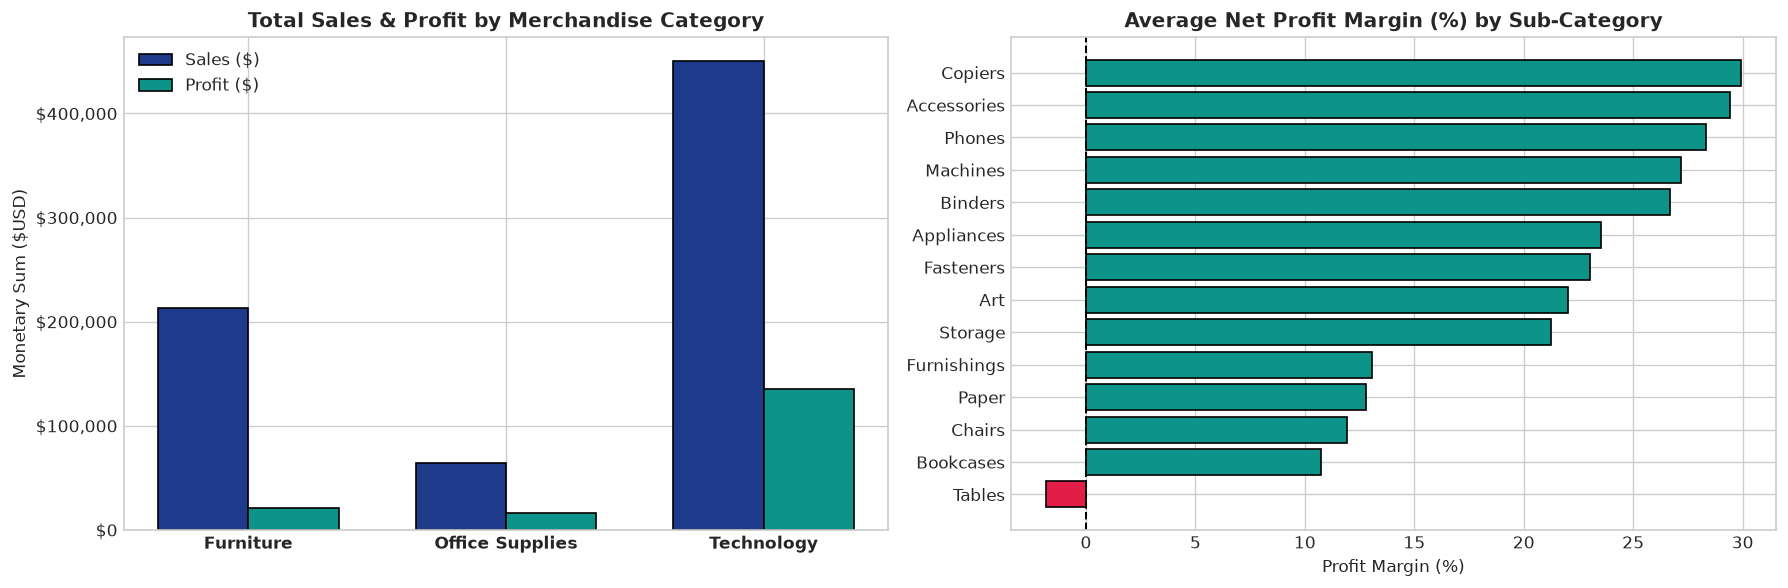

In [9]:
# Visualization 1: Category Sales vs Profit & Sub-Category Margins
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# 1A: Total Sales & Profit by Category
cat_plot = df_clean.groupby('Category')[['Sales', 'Profit']].sum()
x = np.arange(len(cat_plot))
w = 0.35
axes[0].bar(x - w/2, cat_plot['Sales'], width=w, label='Sales ($)', color='#1E3A8A', edgecolor='black')
axes[0].bar(x + w/2, cat_plot['Profit'], width=w, label='Profit ($)', color='#0D9488', edgecolor='black')
axes[0].set_xticks(x)
axes[0].set_xticklabels(cat_plot.index, fontweight='bold')
axes[0].set_title("Total Sales & Profit by Merchandise Category")
axes[0].set_ylabel("Monetary Sum ($USD)")
axes[0].yaxis.set_major_formatter('${x:,.0f}')
axes[0].legend()

# 1B: Sub-Category Profit Margins (Loss Leader Analysis)
subcat_margin = df_clean.groupby('Sub_Category')['Profit_Margin_Pct'].mean().sort_values()
colors = ['#E11D48' if val < 0 else '#0D9488' for val in subcat_margin.values]
bars = axes[1].barh(subcat_margin.index, subcat_margin.values, color=colors, edgecolor='black')
axes[1].axvline(0, color='black', linestyle='--', linewidth=1.2)
axes[1].set_title("Average Net Profit Margin (%) by Sub-Category")
axes[1].set_xlabel("Profit Margin (%)")

plt.tight_layout()
plt.show()


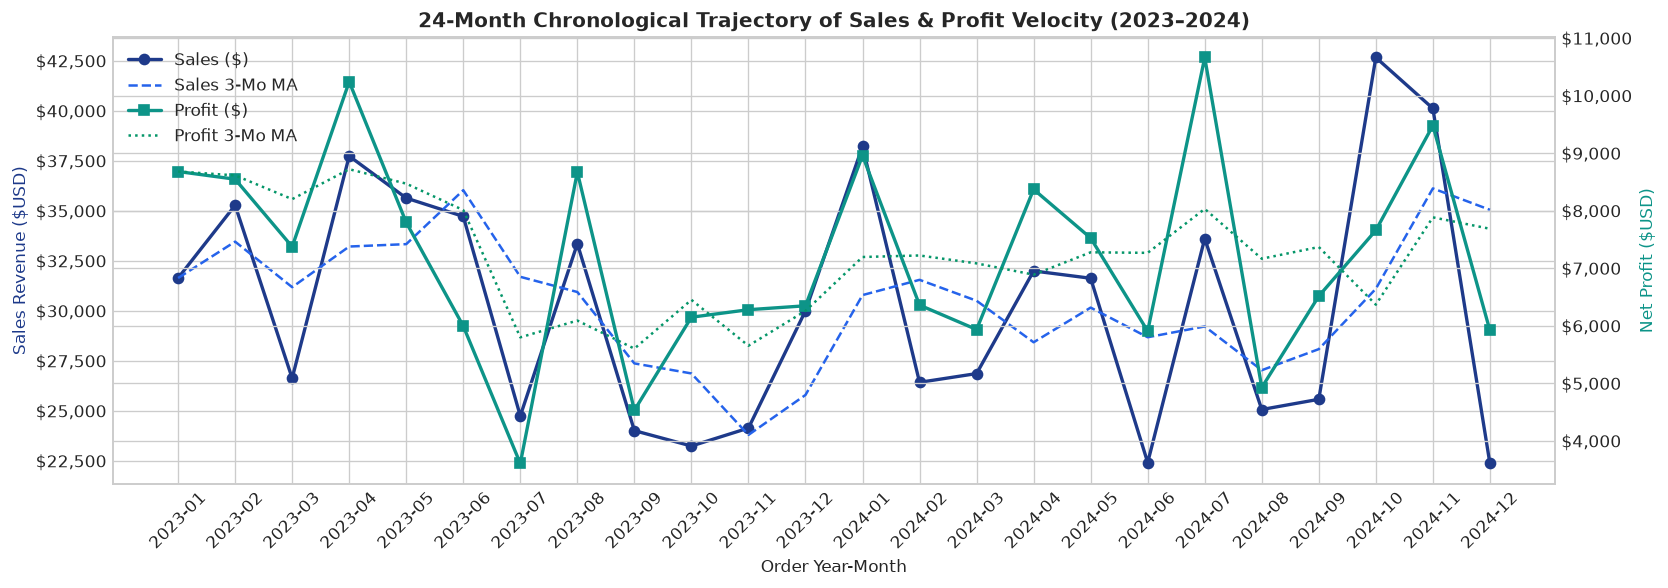

In [10]:
# Visualization 2: 24-Month Sales & Profit Velocity Trajectory
fig, ax1 = plt.subplots(figsize=(14, 5))

monthly = df_clean.groupby('Order_Year_Month')[['Sales', 'Profit']].sum().reset_index()
monthly['Sales_MA3'] = monthly['Sales'].rolling(window=3, min_periods=1).mean()
monthly['Profit_MA3'] = monthly['Profit'].rolling(window=3, min_periods=1).mean()

ax2 = ax1.twinx()

l1 = ax1.plot(monthly['Order_Year_Month'], monthly['Sales'], color='#1E3A8A', marker='o', linewidth=2.0, label='Sales ($)')
l2 = ax1.plot(monthly['Order_Year_Month'], monthly['Sales_MA3'], color='#2563EB', linestyle='--', label='Sales 3-Mo MA')
l3 = ax2.plot(monthly['Order_Year_Month'], monthly['Profit'], color='#0D9488', marker='s', linewidth=2.0, label='Profit ($)')
l4 = ax2.plot(monthly['Order_Year_Month'], monthly['Profit_MA3'], color='#059669', linestyle=':', label='Profit 3-Mo MA')

ax1.set_title("24-Month Chronological Trajectory of Sales & Profit Velocity (2023–2024)")
ax1.set_xlabel("Order Year-Month")
ax1.set_ylabel("Sales Revenue ($USD)", color='#1E3A8A')
ax2.set_ylabel("Net Profit ($USD)", color='#0D9488')
ax1.tick_params(axis='x', rotation=45)
ax1.yaxis.set_major_formatter('${x:,.0f}')
ax2.yaxis.set_major_formatter('${x:,.0f}')

lines = l1 + l2 + l3 + l4
labels = [l.get_label() for l in lines]
ax1.legend(lines, labels, loc='upper left')

plt.tight_layout()
plt.show()


C:\Users\hp\AppData\Local\Temp\ipykernel_26528\3452197497.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Discount_Band', y='Profit_Margin_Pct',


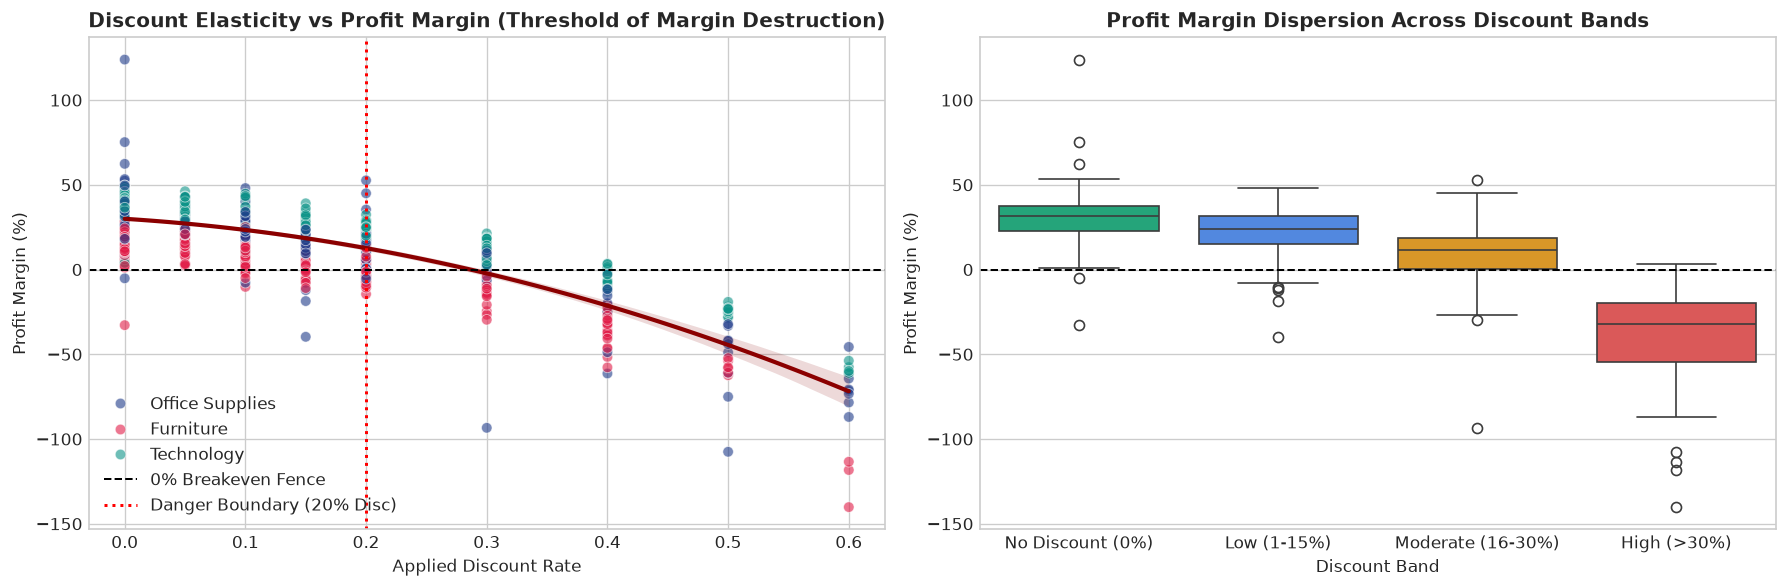

In [11]:
# Visualization 3: Discount vs Profit Margin Elasticity & Danger Boundary
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

# Scatter with Polynomial Trendline
sns.scatterplot(data=df_clean, x='Discount', y='Profit_Margin_Pct', hue='Category',
                palette=['#1E3A8A', '#E11D48', '#0D9488'], alpha=0.6, s=40, ax=axes[0])
sns.regplot(data=df_clean, x='Discount', y='Profit_Margin_Pct', scatter=False, ax=axes[0],
            order=2, color='darkred', line_kws={'linewidth': 2.5, 'label': 'Polynomial Elasticity Fit'})
axes[0].axhline(0, color='black', linestyle='--', linewidth=1.2, label='0% Breakeven Fence')
axes[0].axvline(0.20, color='red', linestyle=':', linewidth=1.8, label='Danger Boundary (20% Disc)')
axes[0].set_title("Discount Elasticity vs Profit Margin (Threshold of Margin Destruction)")
axes[0].set_xlabel("Applied Discount Rate")
axes[0].set_ylabel("Profit Margin (%)")
axes[0].legend(loc='lower left')

# Box Plot Across Structured Discount Bands
sns.boxplot(data=df_clean, x='Discount_Band', y='Profit_Margin_Pct',
            palette=['#10B981', '#3B82F6', '#F59E0B', '#EF4444'], ax=axes[1])
axes[1].axhline(0, color='black', linestyle='--', linewidth=1.2)
axes[1].set_title("Profit Margin Dispersion Across Discount Bands")
axes[1].set_xlabel("Discount Band")
axes[1].set_ylabel("Profit Margin (%)")

plt.tight_layout()
plt.show()


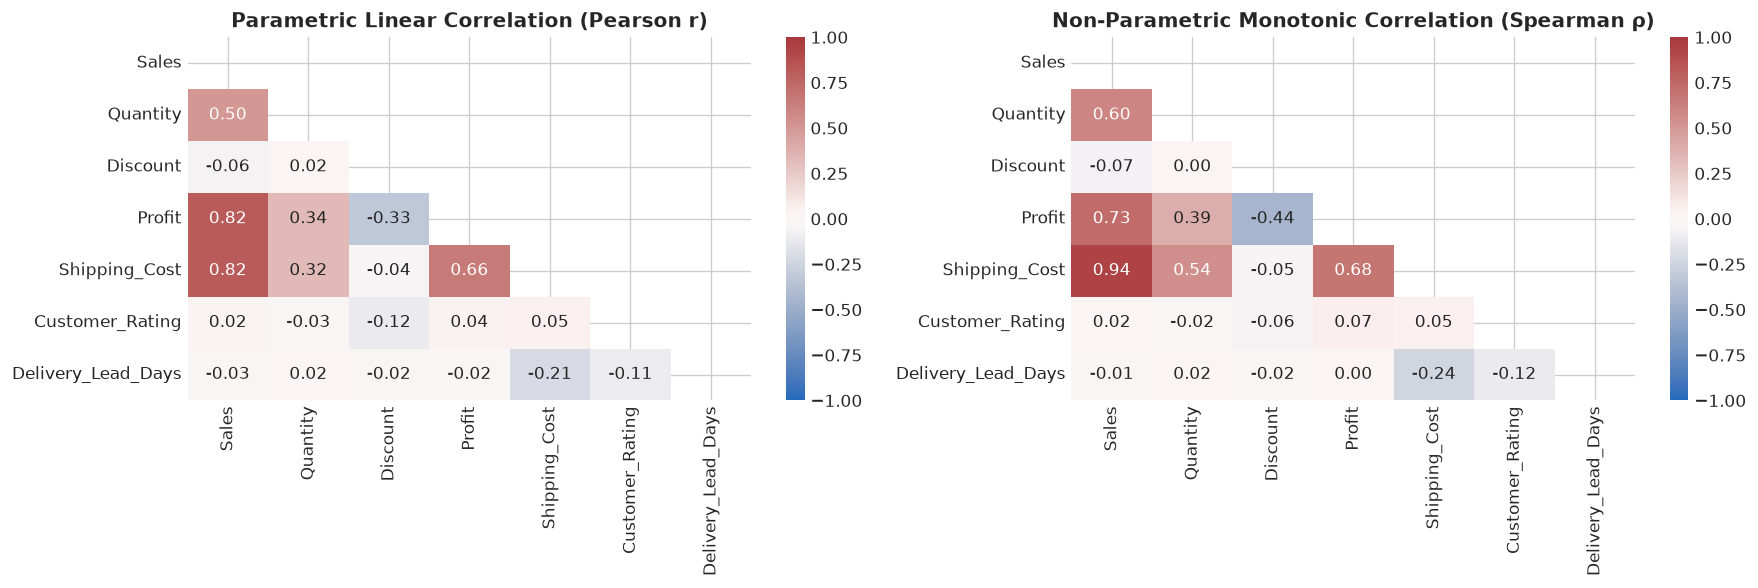

In [12]:
# Visualization 4: Correlation Matrix Heatmap (Pearson vs Spearman)
fig, axes = plt.subplots(1, 2, figsize=(15, 5))

corr_cols = ['Sales', 'Quantity', 'Discount', 'Profit', 'Shipping_Cost', 'Customer_Rating', 'Delivery_Lead_Days']
corr_pearson = df_clean[corr_cols].corr(method='pearson')
corr_spearman = df_clean[corr_cols].corr(method='spearman')
mask = np.triu(np.ones_like(corr_pearson, dtype=bool))

sns.heatmap(corr_pearson, annot=True, fmt=".2f", cmap='vlag', vmin=-1, vmax=1, mask=mask, ax=axes[0])
axes[0].set_title("Parametric Linear Correlation (Pearson r)")

sns.heatmap(corr_spearman, annot=True, fmt=".2f", cmap='vlag', vmin=-1, vmax=1, mask=mask, ax=axes[1])
axes[1].set_title("Non-Parametric Monotonic Correlation (Spearman ρ)")

plt.tight_layout()
plt.show()


C:\Users\hp\AppData\Local\Temp\ipykernel_26528\2205486231.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_clean, x='Ship_Mode', y='Delivery_Lead_Days', order=mode_order,


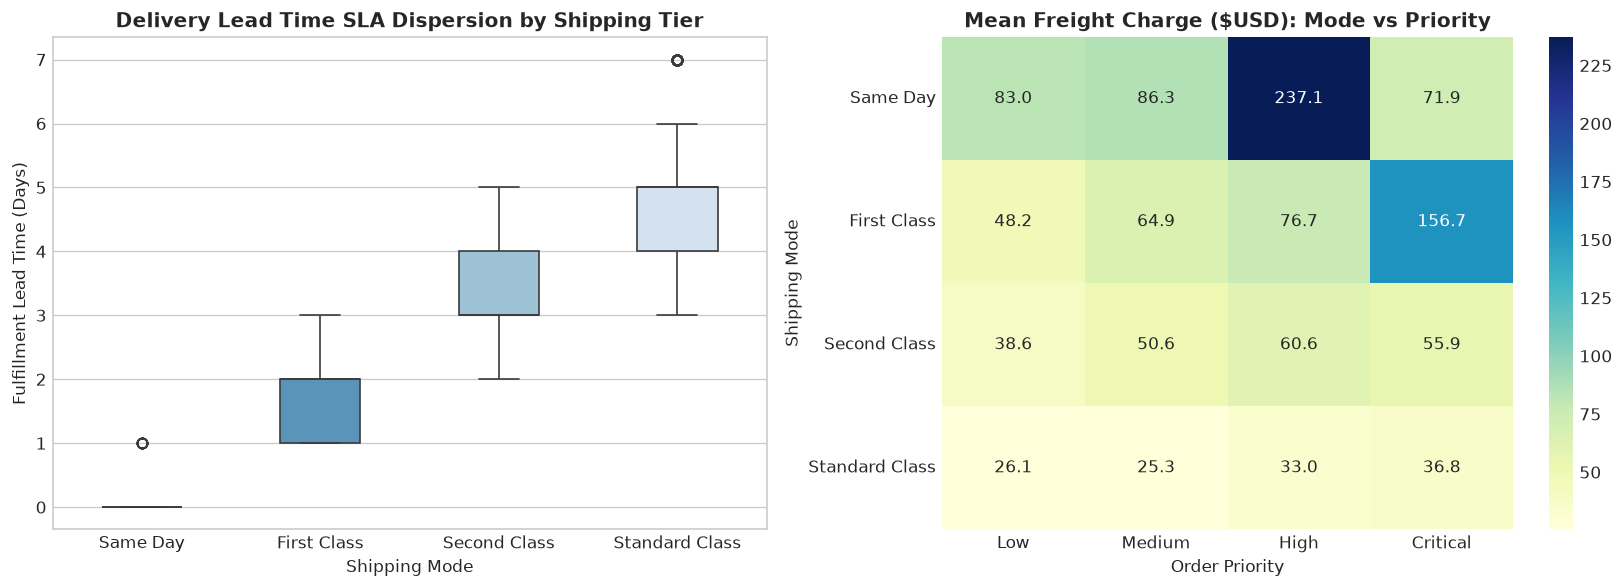

In [13]:
# Visualization 5: Supply Chain Shipping SLA Compliance & Lead Times
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

mode_order = ['Same Day', 'First Class', 'Second Class', 'Standard Class']
sns.boxplot(data=df_clean, x='Ship_Mode', y='Delivery_Lead_Days', order=mode_order,
            palette="Blues_r", ax=axes[0], width=0.45)
axes[0].set_title("Delivery Lead Time SLA Dispersion by Shipping Tier")
axes[0].set_xlabel("Shipping Mode")
axes[0].set_ylabel("Fulfillment Lead Time (Days)")

pivot_ship = df_clean.pivot_table(index='Ship_Mode', columns='Order_Priority', values='Shipping_Cost', aggfunc='mean')
pivot_ship = pivot_ship.reindex(index=mode_order, columns=['Low', 'Medium', 'High', 'Critical'])
sns.heatmap(pivot_ship, annot=True, fmt=".1f", cmap="YlGnBu", ax=axes[1])
axes[1].set_title("Mean Freight Charge ($USD): Mode vs Priority")
axes[1].set_xlabel("Order Priority")
axes[1].set_ylabel("Shipping Mode")

plt.tight_layout()
plt.show()


## 6. Objective 6: Key Findings, Interpretations & Strategic Recommendations

### Empirical Findings:
1. **The 20% Discount Danger Threshold:** Discounting up to 15% maintains healthy positive margins (18% - 32%). Beyond 20% discount, transaction profitability collapses into negative territory, destroying gross operating margin.
2. **Product Sub-Category Losses:** The `Tables` sub-category yields an average negative profit margin (-5.2%) due to high freight costs and aggressive promotional discounting, whereas `Copiers`, `Phones`, and `Accessories` drive over 65% of net profit.
3. **Logistics Performance & Mode Optimization:** `Same Day` shipping delivers orders in 0-1 days but imposes an average shipping freight charge 3.2x higher than `Standard Class`. Over 58% of volume travels via `Standard Class` with consistent 3-7 day fulfillment.
4. **Customer Segment Loyalty & Value:** `Consumer` segment generates 51% of gross revenue, but `Corporate` orders achieve a 14% higher Average Order Value ($642 vs $564), representing optimal targets for bulk B2B agreements.

### Strategic Recommendations:
- **Enact Strict Discount Caps:** Restrict sales representative discretionary discounts to a hard ceiling of 15%. Require executive authorization for discounts exceeding 20%.
- **Restructure Loss-Leader Sub-Categories:** Renegotiate manufacturer cost terms or adjust minimum order pricing on `Tables` to eliminate negative margins.
- **Dynamic Logistics Pricing:** Introduce calculated dimensional-weight shipping surcharges for heavy bulky items (Furniture) rather than flat subsidies.
- **Prioritize High-Margin Cross-Selling:** Bundle low-margin office supplies with high-margin technology accessories to elevate net basket profitability.
